# Can an autoencoder rediscover ENSO? (ERA5 version)

Starter notebook for the AI in Climate course project.

**Idea.** Train a small autoencoder on monthly sea surface temperature (SST) anomaly maps over the tropical Pacific and ask:

1. How well does it reconstruct unseen months compared with PCA/EOFs using the same number of dimensions?
2. Does its latent space capture ENSO, i.e. does a latent coordinate track the Niño3.4 index?
3. Does the nonlinearity buy anything: El Niño / La Niña asymmetry, and Eastern Pacific (EP) vs Central Pacific (CP) El Niños?

**Pipeline.** ERA5 SST from CDS → anomalies → PCA baseline → autoencoder → compare.

Everything runs on a laptop CPU in a few minutes.

In [1]:
from pathlib import Path
import glob

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.decomposition import PCA

# ---------------- configuration ----------------
LAT = (-20, 20)          # tropical Pacific box
LON = (120, 280)         # 120E to 80W, in 0-360 longitude
START_YEAR = 1980        # ERA5 download covers 1980-2023
GRID_DEG = 2.0           # coarsen ERA5's 0.25 deg grid to this
TRAIN_END = 2012         # train on START_YEAR..TRAIN_END, test on the years after
LATENT_DIM = 2           # main experiment; the sweep below tries several sizes
VARIATIONAL = False      # True turns the autoencoder into a VAE
BETA = 0.1               # KL weight when VARIATIONAL is True
SEED = 0

DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
torch.manual_seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Data: ERA5 monthly SST

ERA5 monthly averaged reanalysis, sea surface temperature, downloaded from the Copernicus CDS (1980–2023, 0.25°).
The file is read from `data/` (any subfolder), cropped to the tropical Pacific and block-averaged to 2°, the same grid as the ERSST version.

In [2]:
hits = sorted(glob.glob(str(DATA_DIR / "**" / "data_stream-moda*.nc"), recursive=True))
assert hits, "Put the ERA5 file from CDS (data_stream-moda*.nc) somewhere under data/"
ds = xr.open_dataset(hits[0]).rename({"valid_time": "time", "latitude": "lat", "longitude": "lon"})
sst = ds["sst"] - 273.15
sst = sst.drop_vars([c for c in sst.coords if c not in ("time", "lat", "lon")])
sst = sst.assign_coords(lon=sst.lon % 360).sortby("lon").sortby("lat")
sst = sst.sel(lat=slice(*LAT), lon=slice(*LON), time=slice(str(START_YEAR), None))
step = int(round(GRID_DEG / float(sst.lon[1] - sst.lon[0])))
sst = sst.coarsen(lat=step, lon=step, boundary="trim").mean()
print(hits[0])
print(sst.sizes, "|", str(sst.time.values[0])[:7], "to", str(sst.time.values[-1])[:7])

data\CDS Data\data_stream-moda_stepType-avgua.nc
Frozen({'time': 528, 'lat': 20, 'lon': 80}) | 1980-01 to 2023-12


## 2. Anomalies

Subtract the monthly climatology and a linear trend, both fitted **on the training years only** so nothing leaks from the test period. Then flatten each map into a vector of ocean grid points, weighted by √cos(latitude) so every point counts in proportion to its area (the standard EOF convention).

In [3]:
time = pd.DatetimeIndex(sst.time.values)
is_train = time.year <= TRAIN_END

clim = sst.isel(time=is_train).groupby("time.month").mean("time")
anom = sst.groupby("time.month") - clim

# linear trend per grid point, fitted on the training period
t = np.arange(len(time), dtype=float)
A = anom.values.reshape(len(time), -1)
ocean = ~np.isnan(A).any(axis=0)
coef = np.polyfit(t[is_train], A[is_train][:, ocean], 1)
A_ocean = A[:, ocean] - (np.outer(t, coef[0]) + coef[1])

weights = np.sqrt(np.cos(np.deg2rad(anom.lat.values)))[:, None] * np.ones(anom.lon.size)
w = weights.ravel()[ocean]
X = (A_ocean * w).astype(np.float32)          # (n_months, n_ocean_points)

X_train, X_test = X[is_train], X[~is_train]
print(f"{X.shape[1]} ocean points | train {X_train.shape[0]} months | test {X_test.shape[0]} months")

nlat, nlon = anom.lat.size, anom.lon.size

def to_map(vec):
    # weighted ocean vector -> (lat, lon) anomaly map in degC, land as NaN
    out = np.full(nlat * nlon, np.nan)
    out[ocean] = vec / w
    return out.reshape(nlat, nlon)

def plot_map(ax, field, title, vmax=None):
    vmax = vmax or np.nanmax(np.abs(field))
    im = ax.pcolormesh(anom.lon, anom.lat, field, cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="auto")
    ax.set_title(title, fontsize=10); ax.set_aspect("equal")
    return im

1572 ocean points | train 396 months | test 132 months


## 3. ENSO indices for evaluation

These are **not** used to train anything, only to interpret the results.

- **Niño3.4**: mean anomaly over 5°S–5°N, 170°W–120°W, smoothed with a 3-month running mean (like NOAA's ONI).
- **EP vs CP El Niño**: for each winter (DJF) with Niño3.4 ≥ 0.5 °C, call it CP if the standardised Niño4 anomaly (160°E–150°W) exceeds the standardised Niño3 anomaly (150°W–90°W), otherwise EP (in the spirit of Kug et al., 2009). This is a simple rule; published event lists disagree on a few borderline years.

El Niño winters (n3, n4 in standard deviations):
         n34    n3    n4 type
season                       
1982    2.33  2.93  1.02   EP
1986    1.23  1.13  0.92   EP
1987    0.68  0.65  1.01   CP
1991    1.66  1.32  1.29   EP
1994    0.98  0.87  1.21   CP
1997    2.50  3.38  1.32   EP
2002    1.21  0.97  1.45   CP
2004    0.65  0.37  1.35   CP
2006    0.81  0.95  1.10   CP
2009    1.60  1.33  1.76   CP
2014    0.87  0.73  1.41   CP
2015    2.51  2.67  1.93   EP
2018    1.01  0.93  1.48   CP
2019    0.77  0.45  1.53   CP


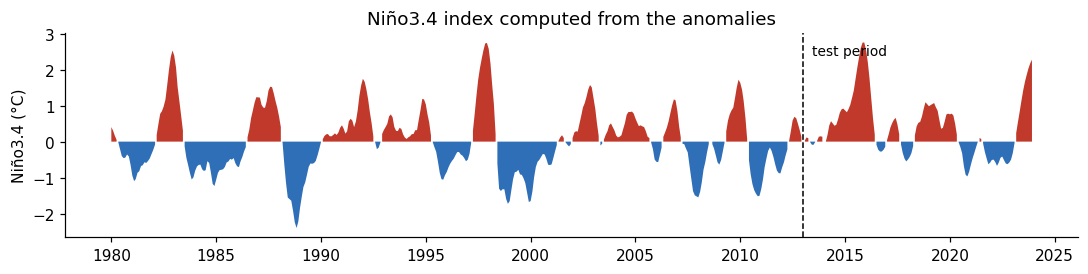

In [4]:
A_detr = np.full_like(A, np.nan); A_detr[:, ocean] = A_ocean
anom_d = xr.DataArray(A_detr.reshape(anom.shape), coords=anom.coords, dims=anom.dims)

def box_mean(lat, lon):
    return anom_d.sel(lat=slice(*lat), lon=slice(*lon)).mean(["lat", "lon"]).to_series()

nino34 = box_mean((-5, 5), (190, 240)).rolling(3, center=True, min_periods=1).mean()
nino3 = box_mean((-5, 5), (210, 270))
nino4 = box_mean((-5, 5), (160, 210))
nino3, nino4 = nino3 / nino3.std(), nino4 / nino4.std()   # standardised so the two boxes are comparable

# DJF seasons labelled by the year of the December
djf = pd.DataFrame({"n34": nino34, "n3": nino3, "n4": nino4})
djf = djf[djf.index.month.isin([12, 1, 2])]
djf["season"] = djf.index.year - (djf.index.month < 12)
djf = djf.groupby("season").agg(["mean", "count"])
djf = djf.xs("mean", axis=1, level=1)[djf[("n34", "count")] == 3]   # complete winters only
el_nino = djf[djf.n34 >= 0.5].copy()
el_nino["type"] = np.where(el_nino.n4 > el_nino.n3, "CP", "EP")
print("El Niño winters (n3, n4 in standard deviations):")
print(el_nino.round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 2.6))
ax.fill_between(nino34.index, nino34, 0, where=nino34 > 0, color="#c0392b", lw=0)
ax.fill_between(nino34.index, nino34, 0, where=nino34 < 0, color="#2e6fb7", lw=0)
ax.axvline(pd.Timestamp(f"{TRAIN_END + 1}-01-01"), color="k", ls="--", lw=1)
ax.text(pd.Timestamp(f"{TRAIN_END + 1}-06-01"), ax.get_ylim()[1] * 0.8, "test period", fontsize=9)
ax.set_ylabel("Niño3.4 (°C)"); ax.set_title("Niño3.4 index computed from the anomalies")
plt.tight_layout(); plt.show()

## 4. Baseline: PCA / EOFs

PCA on the weighted anomalies gives the classic EOFs. EOF1 should look like the canonical El Niño pattern and PC1 should correlate strongly with Niño3.4.

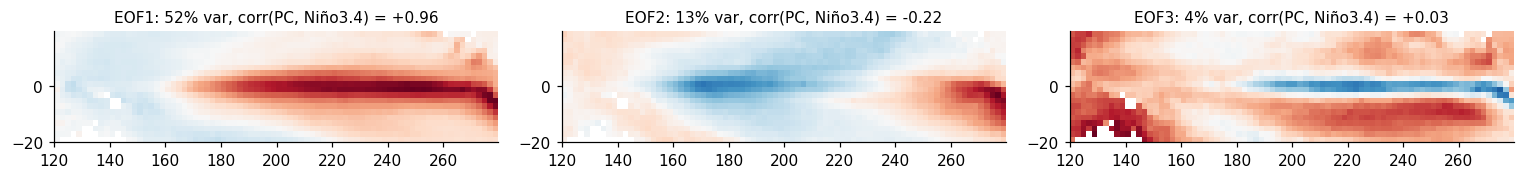

In [5]:
pca = PCA(n_components=10).fit(X_train)
pcs = pca.transform(X)

fig, axes = plt.subplots(1, 3, figsize=(14, 2.8))
for i, ax in enumerate(axes):
    r = np.corrcoef(pcs[:, i], nino34.values)[0, 1]
    plot_map(ax, to_map(pca.components_[i] * pcs[:, i].std()),
             f"EOF{i+1}: {pca.explained_variance_ratio_[i]:.0%} var, corr(PC, Niño3.4) = {r:+.2f}")
plt.tight_layout(); plt.show()

## 5. Autoencoder

A small fully connected network: about 1,700 ocean points → 128 → 32 → latent → 32 → 128 → ocean points. With only a few hundred training maps, the model has to stay small and regularised (dropout, weight decay, early stopping on the last 15% of training years).

Set `VARIATIONAL = True` in the config cell to train a VAE instead; `BETA` controls how strongly the latent space is pulled towards a standard normal.

A convolutional encoder is a natural upgrade later, but the fully connected version is easier to reason about and is a fair comparison with PCA.

stopped after 140 epochs, best validation MSE 0.1726


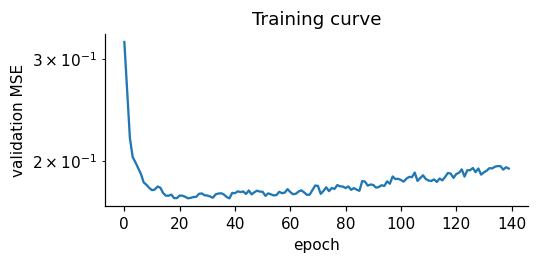

In [6]:
class AE(nn.Module):
    def __init__(self, n_in, k, hidden=(128, 32), variational=False, dropout=0.1):
        super().__init__()
        self.variational = variational
        enc, d = [], n_in
        for h in hidden:
            enc += [nn.Linear(d, h), nn.GELU(), nn.Dropout(dropout)]; d = h
        self.encoder = nn.Sequential(*enc)
        self.mu = nn.Linear(d, k)
        self.logvar = nn.Linear(d, k) if variational else None
        dec, d = [], k
        for h in reversed(hidden):
            dec += [nn.Linear(d, h), nn.GELU()]; d = h
        dec += [nn.Linear(d, n_in)]
        self.decoder = nn.Sequential(*dec)

    def encode(self, x):
        h = self.encoder(x)
        return self.mu(h), (self.logvar(h) if self.variational else None)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar) if (self.variational and self.training) else mu
        return self.decoder(z), mu, logvar


def train_ae(X_tr, k, variational=False, beta=BETA, epochs=3000, lr=1e-3, patience=100, seed=SEED, verbose=False):
    torch.manual_seed(seed)
    n_val = int(0.15 * len(X_tr))                    # last 15% of training years for early stopping
    xt, xv = torch.tensor(X_tr[:-n_val]), torch.tensor(X_tr[-n_val:])
    model = AE(X_tr.shape[1], k, variational=variational)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    best, best_state, wait, history = np.inf, None, 0, []

    def loss_fn(x):
        xh, mu, logvar = model(x)
        loss = ((xh - x) ** 2).mean()
        if variational:
            kl = -0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(1).mean() / x.shape[1]
            loss = loss + beta * kl
        return loss

    for ep in range(epochs):
        model.train()
        for idx in torch.randperm(len(xt)).split(64):
            opt.zero_grad(); loss_fn(xt[idx]).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = ((model(xv)[0] - xv) ** 2).mean().item()
        history.append(v)
        if v < best - 1e-6:
            best, best_state, wait = v, {n: p.clone() for n, p in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait > patience:
                break
    model.load_state_dict(best_state); model.eval()
    if verbose:
        print(f"stopped after {ep + 1} epochs, best validation MSE {best:.4f}")
    return model, history


def ae_encode(model, X_):
    with torch.no_grad():
        return model.encode(torch.tensor(X_))[0].numpy()

def ae_reconstruct(model, X_):
    with torch.no_grad():
        return model(torch.tensor(X_))[0].numpy()

model, history = train_ae(X_train, LATENT_DIM, variational=VARIATIONAL, verbose=True)
plt.figure(figsize=(5, 2.5)); plt.plot(history); plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("validation MSE"); plt.title("Training curve"); plt.tight_layout(); plt.show()

## 6. Reconstruction on the test years: AE vs PCA

Explained variance on the **held-out** years, for several latent sizes. If the autoencoder beats PCA at small sizes, it is finding structure that a linear basis needs extra dimensions for. If it doesn't, that is a legitimate finding too: ENSO is to a large degree linear.

              PCA     AE
latent dim              
1           0.524  0.494
2           0.587  0.558
3           0.656  0.612
4           0.709  0.612
6           0.754  0.628
8           0.798  0.663


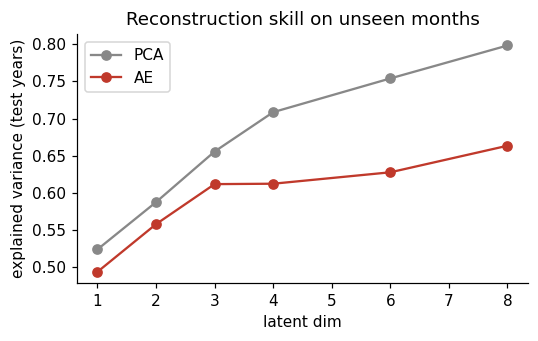

In [7]:
def explained_var(X_true, X_hat):
    return 1 - ((X_true - X_hat) ** 2).sum() / ((X_true - X_train.mean(0)) ** 2).sum()

ks = [1, 2, 3, 4, 6, 8]
rows = []
for k in ks:
    p = PCA(n_components=k).fit(X_train)
    pca_ev = explained_var(X_test, p.inverse_transform(p.transform(X_test)))
    m = model if k == LATENT_DIM else train_ae(X_train, k, variational=VARIATIONAL)[0]
    rows.append({"latent dim": k, "PCA": pca_ev, "AE": explained_var(X_test, ae_reconstruct(m, X_test))})
scores = pd.DataFrame(rows).set_index("latent dim")
print(scores.round(3).to_string())

ax = scores.plot(marker="o", figsize=(5, 3.2), color=["#888888", "#c0392b"])
ax.set_ylabel("explained variance (test years)"); ax.set_title("Reconstruction skill on unseen months")
plt.tight_layout(); plt.show()

## 7. Does the latent space capture ENSO?

Autoencoder latent axes are not ordered or unique (any rotation of the latent space works equally well for the decoder), so we look at the correlation of **each** latent coordinate with Niño3.4, and at a linear fit of Niño3.4 from all of them together.

In [8]:
Z = ae_encode(model, X)
n34 = nino34.values
for i in range(LATENT_DIM):
    print(f"corr(z{i+1}, Niño3.4) = {np.corrcoef(Z[:, i], n34)[0, 1]:+.2f}")

def linear_r2(F, y, train):
    F1 = np.c_[F, np.ones(len(F))]
    beta = np.linalg.lstsq(F1[train], y[train], rcond=None)[0]
    pred = F1 @ beta
    return 1 - ((y - pred)[~train] ** 2).sum() / ((y - y[train].mean())[~train] ** 2).sum()

print(f"\nLinear fit of Niño3.4 on test years: R² from AE latents = {linear_r2(Z, n34, is_train):.2f}, "
      f"from first {LATENT_DIM} PCs = {linear_r2(pcs[:, :LATENT_DIM], n34, is_train):.2f}")

corr(z1, Niño3.4) = +0.62
corr(z2, Niño3.4) = -0.89

Linear fit of Niño3.4 on test years: R² from AE latents = 0.94, from first 2 PCs = 0.95


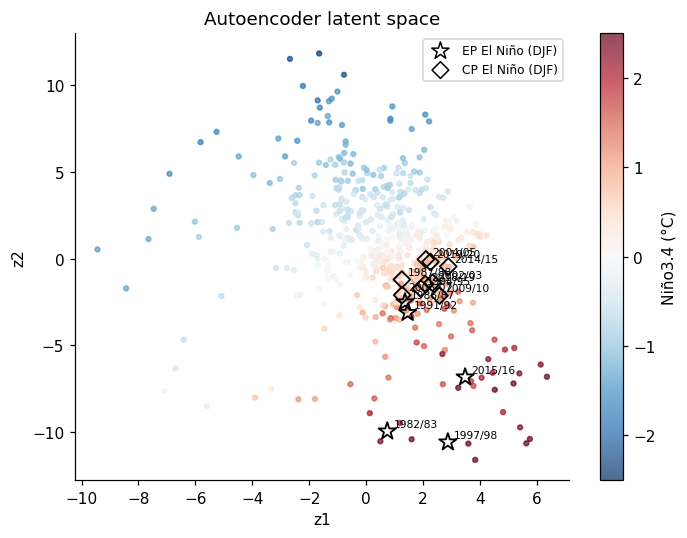

In [9]:
# Latent space coloured by Niño3.4, with El Niño winters marked by type
if LATENT_DIM >= 2:
    fig, ax = plt.subplots(figsize=(6.5, 5))
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=n34, cmap="RdBu_r", vmin=-2.5, vmax=2.5, s=10, alpha=0.7)
    plt.colorbar(sc, label="Niño3.4 (°C)")
    z_df = pd.DataFrame(Z[:, :2], index=time, columns=["z1", "z2"])
    for season, row in el_nino.iterrows():
        sel = z_df[((z_df.index.year == season) & (z_df.index.month == 12)) |
                   ((z_df.index.year == season + 1) & (z_df.index.month <= 2))].mean()
        ax.scatter(*sel, marker="*" if row.type == "EP" else "D", s=140 if row.type == "EP" else 60,
                   facecolor="none", edgecolor="k", lw=1.2)
        ax.annotate(f"{season}/{str(season + 1)[2:]}", sel, fontsize=7, xytext=(4, 3), textcoords="offset points")
    ax.scatter([], [], marker="*", s=140, facecolor="none", edgecolor="k", label="EP El Niño (DJF)")
    ax.scatter([], [], marker="D", s=60, facecolor="none", edgecolor="k", label="CP El Niño (DJF)")
    ax.legend(loc="best", fontsize=8); ax.set_xlabel("z1"); ax.set_ylabel("z2")
    ax.set_title("Autoencoder latent space"); plt.tight_layout(); plt.show()

## 8. What has the decoder learned?

Walk along each latent axis and decode. A linear method (PCA) can only produce **one** pattern that flips sign between positive and negative values. If the decoded "positive" and "negative" ends look different (for example, warm anomalies peaking further east than cold ones), the autoencoder has picked up the El Niño / La Niña asymmetry.

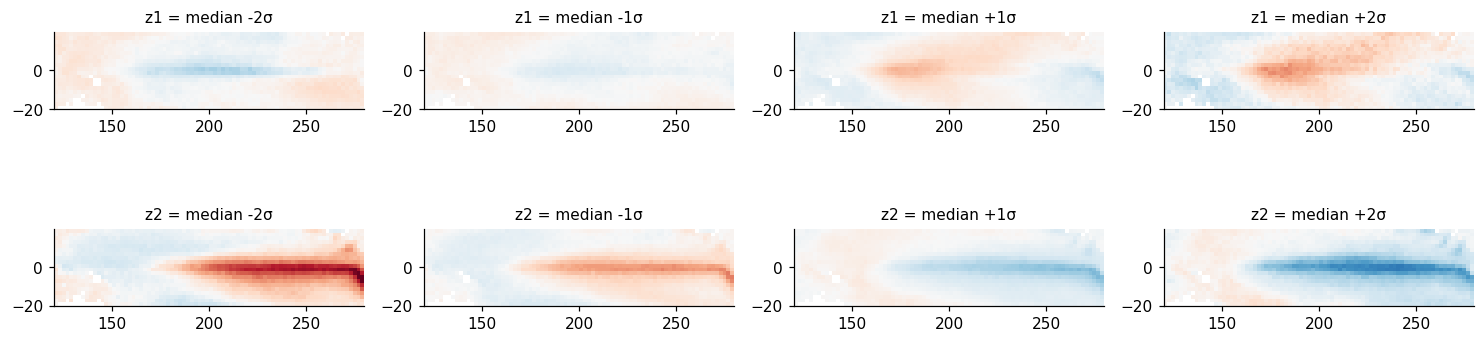

In [10]:
steps = [-2, -1, 1, 2]
fig, axes = plt.subplots(LATENT_DIM, len(steps), figsize=(3.4 * len(steps), 2.1 * LATENT_DIM), squeeze=False)
z0 = np.median(Z, axis=0)
for i in range(LATENT_DIM):
    sd = Z[:, i].std()
    for j, s in enumerate(steps):
        z = z0.copy(); z[i] += s * sd
        with torch.no_grad():
            field = to_map(model.decoder(torch.tensor(z[None], dtype=torch.float32)).numpy()[0])
        plot_map(axes[i, j], field, f"z{i+1} = median {s:+d}σ", vmax=3)
plt.tight_layout(); plt.show()

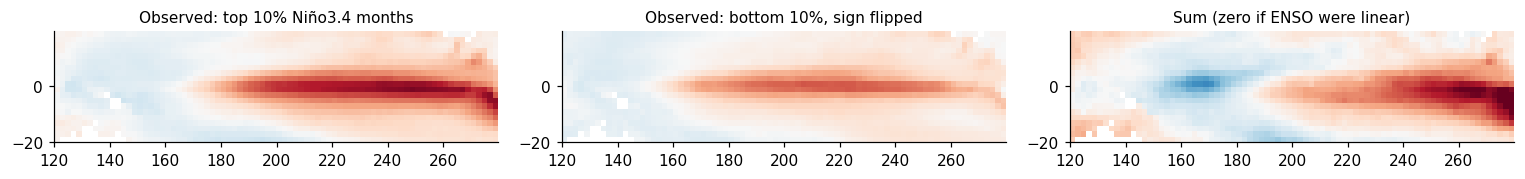

In [11]:
# Composite check of the asymmetry in the data itself: strongest El Niño vs strongest La Niña months
X_maps = np.stack([to_map(x) for x in X])
warm = X_maps[n34 > np.quantile(n34, 0.9)].mean(0)
cold = X_maps[n34 < np.quantile(n34, 0.1)].mean(0)
fig, axes = plt.subplots(1, 3, figsize=(14, 2.8))
plot_map(axes[0], warm, "Observed: top 10% Niño3.4 months", vmax=3)
plot_map(axes[1], -cold, "Observed: bottom 10%, sign flipped", vmax=3)
plot_map(axes[2], warm + cold, "Sum (zero if ENSO were linear)", vmax=1.5)
plt.tight_layout(); plt.show()

## 9. Where to take it next

Pick one or two of these for the project:

- **Fair comparison.** Repeat the AE runs over several seeds and report mean ± spread; vary the train/test split.
- **VAE and ENSO diversity.** Set `VARIATIONAL = True`, try 2–3 latent dims, and test whether EP and CP events separate better than in PC space (e.g. a simple classifier on latents vs PCs).
- **Asymmetry.** Quantify the difference between decoded warm and cold patterns (e.g. the longitude of maximum anomaly) and compare with the observed composites above.
- **Latent-space forecasting.** Predict z(t + 3 or 6 months) from z(t), z(t−1), … with a linear model or small MLP, decode, and compare Niño3.4 skill against persistence and a PC-based forecast.
- **More data.** Train on CMIP6 piControl SST (thousands of model years) and test on observations; this addresses the small-sample problem directly.
- **More variables.** Add thermocline depth or zonal wind stress (e.g. ORAS5, ERA5) as extra input channels.
- **Anomaly detection.** Look at reconstruction error over time: which months does the model find most unusual?

Useful references: Kug, Jin & An (2009) on EP/CP El Niño; Capotondi et al. (2015) *Understanding ENSO diversity*; Ham, Kim & Luo (2019) on deep-learning ENSO forecasts.